Introduction to NLP and sequential data

Why is text difficult for neural networks?
Consider these two sentences:
- "The movie was good."
- "The movie was not good."
Only one word changes, but the meaning changes significantly.

A model must learn not only which words appear but also how words relate to one another.

This is why sequence modeling matters.

2. How do we represent text numerically?
Neural networks cannot directly calculate using strings such as "amazing" or "boring".

We must represent text as numbers.
movie was amazing → [1, 2, 3]

These numbers are identifiers, not sentiment scores. A higher token ID does not imply a more positive word.

An Embedding layer will later convert these token IDs into learned vectors.

In [1]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb

vocab_size = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("First review:", X_train[0][:20])
print("First label:", y_train[0])


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First label: 1


Labels represent:
- 0 = Negative
- 1 = Positive

In [2]:

word_index = imdb.get_word_index()

reverse_word_index = {
    index + 3: word
    for word, index in word_index.items()
}

reverse_word_index[0] = "[PAD]"
reverse_word_index[1] = "[START]"
reverse_word_index[2] = "[OOV]"
reverse_word_index[3] = "[UNUSED]"

decoded_review = " ".join(
    reverse_word_index.get(i, "?")
    for i in X_train[0]
)

print(decoded_review)
print("Sentiment:", "Positive" if y_train[0] == 1 else "Negative")


1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
[START] this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert [OOV] is an amazing actor and now the same being director [OOV] father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for [OOV] and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also [OOV] to the two little boy's that played the [OOV] of norman and paul they were just brilliant children are often left out of the [OOV] list i think because the stars that play them all grown up are such a big profile for the whole film but these c

Index	Token	Purpose

0	<PAD>	Fills empty space to make all reviews equal length

1	<START>	Marks the beginning of a review

2	<OOV>	Replaces rare or unknown words

3	<UNUSED>	Reserved spare slot for custom tokens

Why do we need padding?
Movie reviews have different lengths. Some contain 50 tokens, while others contain 100.

For efficient batch processing, we'll make every input sequence the same length.

In [3]:

from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 200

X_train_pad = pad_sequences(
    X_train,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)


Training shape: (25000, 200)
Testing shape: (25000, 200)


Shorter reviews are padded with zeros. Longer reviews are truncated to 200 tokens. This makes training easier, but some information from longer reviews is lost.

In [4]:

for i in range(5):
    print(
        f"Review {i}: {len(X_train[i])} tokens, "
        f"Label: {y_train[i]}"
    )


Review 0: 218 tokens, Label: 1
Review 1: 189 tokens, Label: 0
Review 2: 141 tokens, Label: 0
Review 3: 550 tokens, Label: 1
Review 4: 147 tokens, Label: 0


In [5]:

import tensorflow as tf
from tensorflow.keras.layers import Embedding

embedding_layer = Embedding(
    input_dim=10000,
    output_dim=64
)

sample = tf.constant([[5, 10, 25, 30]])

embedded_output = embedding_layer(sample)

print("Input shape:", sample.shape)
print("Output shape:", embedded_output.shape)
print("Number of parameters:", embedding_layer.count_params())

print(embedded_output.numpy()[0, 0, :10])


Input shape: (1, 4)
Output shape: (1, 4, 64)
Number of parameters: 640000
[ 0.03716991  0.02750385  0.04106968 -0.03913554  0.01388038  0.03945531
 -0.00819899 -0.01173434 -0.02419454  0.03961192]


Input shape: (1, 4) — 1 sequence of 4 token IDs.

Output shape: (1, 4, 64) — each of the 4 token IDs is now replaced by a 64-element vector (1 batch × 4 tokens × 64 dimensions).

Number of parameters: 640000 (10000 * 64). Every single number in that (10000, 64) table is a learnable weight updated during training.

embedded_output.numpy()[0, 0, :10]: Converts the tensor to a NumPy array and slices:

0 $\rightarrow$ first (and only) sequence in the batch

0 $\rightarrow$ first token in that sequence (token ID 5):10

$\rightarrow$ the first 10 numbers of its 64-number embedding vector.

LSTM stands for Long Short-Term Memory.

It is a type of recurrent neural network designed to maintain and update information over longer sequences.

An LSTM uses a cell state and several gates to control how information flows.

An LSTM has three main gates.

Forget gate	Controls how much previous cell-state information is retained

Input gate	Controls how much new information is written into the cell state

Output gate	Controls how the updated state influences the hidden output

In [6]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense

vocab_size = 10000
embedding_dim = 64
max_length = 200

model = Sequential([
    Input(shape=(max_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(64),

    Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

Layer (type),Output Shape,Param #,Why that shape & parameter count?
embedding_1,"(None, 200, 64)","640,000","None = dynamic batch size; 200 tokens × 64 dims. Params = 10,000×64=640,000."
lstm,"(None, 64)","33,024","Collapses the 200 time steps into the final 64-dim state. An LSTM has 4 gates (input, forget, cell candidate, output) each with input weights (64×64), recurrent weights (64×64), and bias (64): 4×(64×64+64×64+64)=4×8,256=33,024."
dense,"(None, 1)",65,Maps 64 features to 1 output: 64 weights+1 bias=65.![image.png](
  
)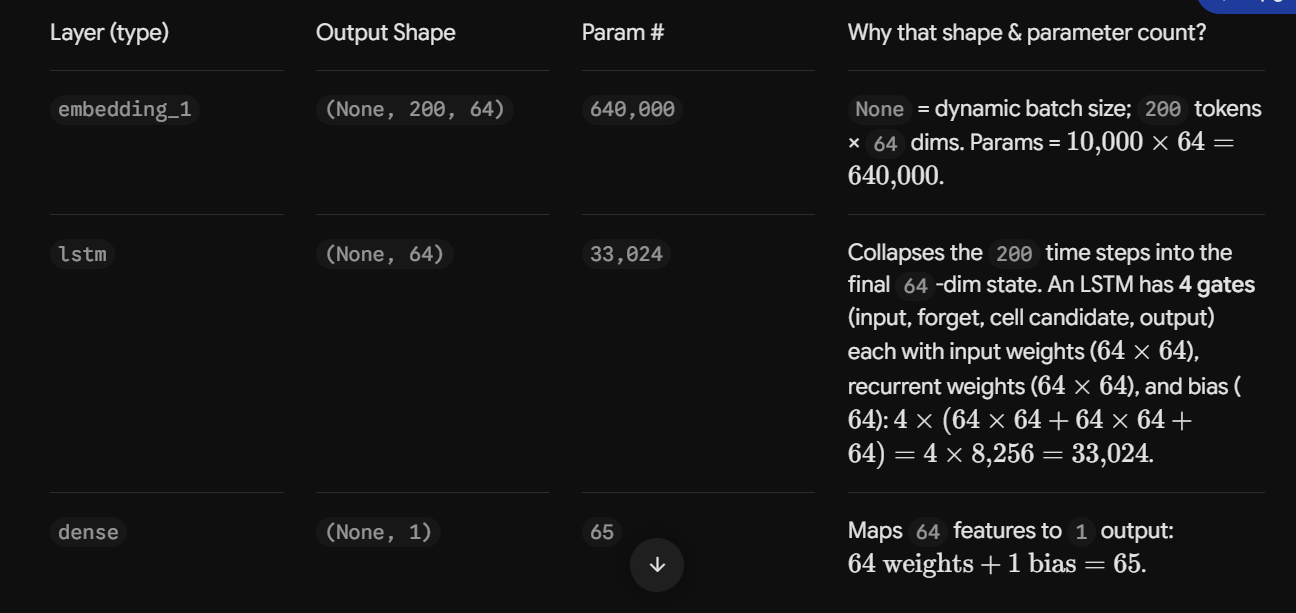

Input(shape=(200,)) — Each review contains 200 token IDs after padding.

Embedding(10000, 64) — Converts every token ID into a vector of 64 numbers. The output for one review has shape (200, 64).

mask_zero=True — Informs compatible downstream layers that token ID 0 represents padding and should be ignored. This is useful because some reviews are shorter than 200 tokens.

LSTM(64) — Processes the sequence and returns a final representation containing 64 values. Because we didn't set return_sequences=True, the layer returns only its final output for each review.


Dense(1, activation="sigmoid") — Produces a number between 0 and 1 representing the model's predicted probability of positive sentiment.

With a classification threshold of 0.5:
- Prediction ≥ 0.5 → Positive
- Prediction below 0.5 → Negative

In [7]:

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [8]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop]
)


Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 118ms/step - accuracy: 0.7571 - loss: 0.4919 - val_accuracy: 0.8516 - val_loss: 0.3573
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 111ms/step - accuracy: 0.8773 - loss: 0.3095 - val_accuracy: 0.8646 - val_loss: 0.3218
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 111ms/step - accuracy: 0.9100 - loss: 0.2373 - val_accuracy: 0.8582 - val_loss: 0.3344
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 35s 111ms/step - accuracy: 0.9332 - loss: 0.1850 - val_accuracy: 0.8660 - val_loss: 0.3775


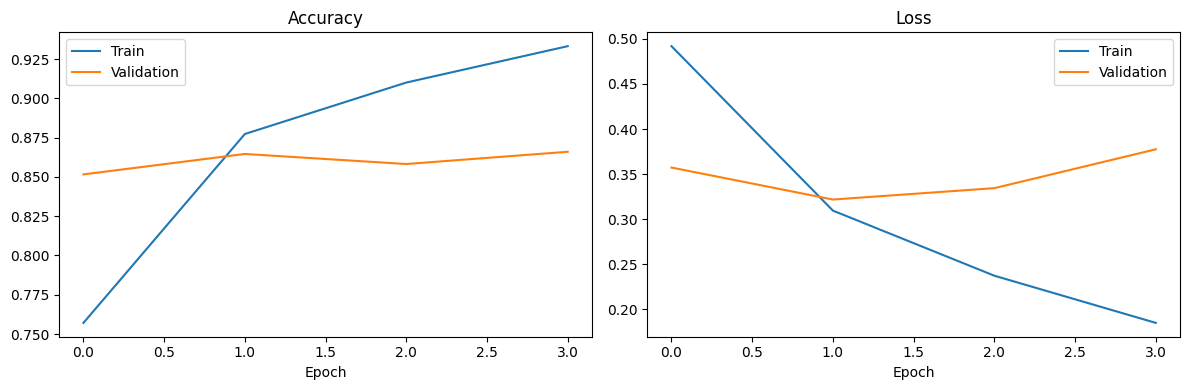

In [9]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()


In [10]:

test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


782/782 ━━━━━━━━━━━━━━━━━━━━ 15s 19ms/step - accuracy: 0.8447 - loss: 0.3539
Test Loss: 0.3539
Test Accuracy: 84.47%


In [11]:

import numpy as np

val_losses = history.history["val_loss"]

best_epoch = np.argmin(val_losses) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:", min(val_losses))

print("\nValidation losses by epoch:")
for epoch, loss in enumerate(val_losses, start=1):
    print(f"Epoch {epoch}: {loss:.4f}")


Best epoch: 2
Best validation loss: 0.3217962980270386

Validation losses by epoch:
Epoch 1: 0.3573
Epoch 2: 0.3218
Epoch 3: 0.3344
Epoch 4: 0.3775


In [12]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout

regularized_model = Sequential([
    Input(shape=(200,)),
    Embedding(10000, 64, mask_zero=True),
    LSTM(32, dropout=0.2),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

regularized_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

regularized_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 652,449 (2.49 MB)

 Trainable params: 652,449 (2.49 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:

from tensorflow.keras.callbacks import EarlyStopping

regularized_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

regularized_history = regularized_model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[regularized_early_stop]
)


Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 28s 82ms/step - accuracy: 0.7610 - loss: 0.4871 - val_accuracy: 0.8466 - val_loss: 0.3582
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 26s 84ms/step - accuracy: 0.8902 - loss: 0.2879 - val_accuracy: 0.8654 - val_loss: 0.3217
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 82ms/step - accuracy: 0.9194 - loss: 0.2233 - val_accuracy: 0.8530 - val_loss: 0.4178
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 42s 84ms/step - accuracy: 0.9363 - loss: 0.1819 - val_accuracy: 0.8652 - val_loss: 0.3928


In [14]:

reg_loss, reg_acc = regularized_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(f"Original LSTM Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Regularized LSTM Test Accuracy: {reg_acc * 100:.2f}%")

best_epoch = (
    np.argmin(regularized_history.history["val_loss"]) + 1
)

print("Best validation epoch:", best_epoch)
print(
    "Best validation loss:",
    min(regularized_history.history["val_loss"])
)


Original LSTM Test Accuracy: 84.47%
Regularized LSTM Test Accuracy: 84.86%
Best validation epoch: 2
Best validation loss: 0.3216548562049866


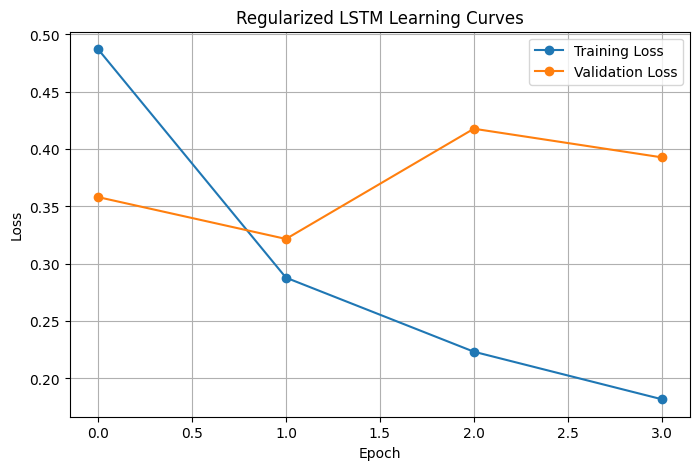

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    regularized_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    regularized_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Regularized LSTM Learning Curves")
plt.legend()
plt.grid(True)
plt.show()


Key learning

A model doesn't necessarily stop learning when validation loss stops improving.

It can continue learning the training dataset while becoming less effective on unseen examples.

This is why we monitor validation loss rather than training loss alone.

Gated Recurrent Unit (GRU)

Purpose: A simplified alternative to LSTM with similar performance.
How it works:

Uses two gates: update and reset

Merges cell state and hidden state into one

Fewer parameters than LSTM

![image.png](
  

)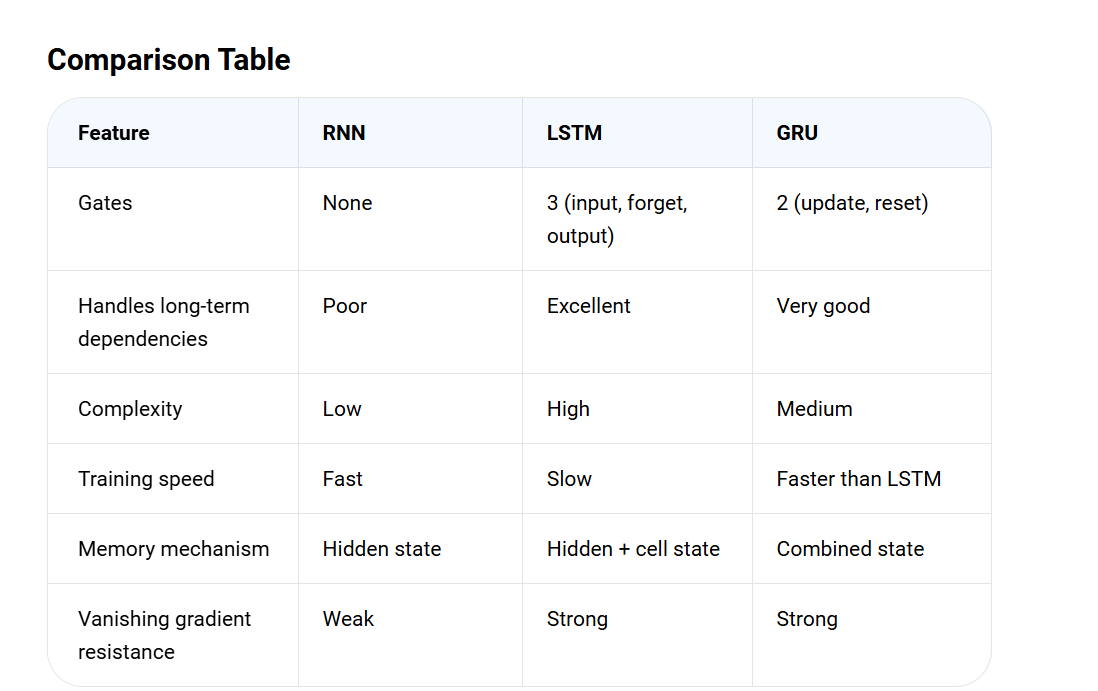

In [16]:

import numpy as np
import tensorflow as tf

from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_pad,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_tr.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test_pad.shape)


Training data: (20000, 200)
Validation data: (5000, 200)
Test data: (25000, 200)


In [17]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Embedding, SimpleRNN, LSTM, GRU, Dense
)

def build_model(model_type):

    if model_type == "SimpleRNN":
        recurrent_layer = SimpleRNN(64)

    elif model_type == "LSTM":
        recurrent_layer = LSTM(64)

    elif model_type == "GRU":
        recurrent_layer = GRU(64)

    else:
        raise ValueError("Invalid model type")

    model = Sequential([
        Input(shape=(200,)),

        Embedding(
            input_dim=10000,
            output_dim=64,
            mask_zero=True
        ),

        recurrent_layer,

        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model



  
)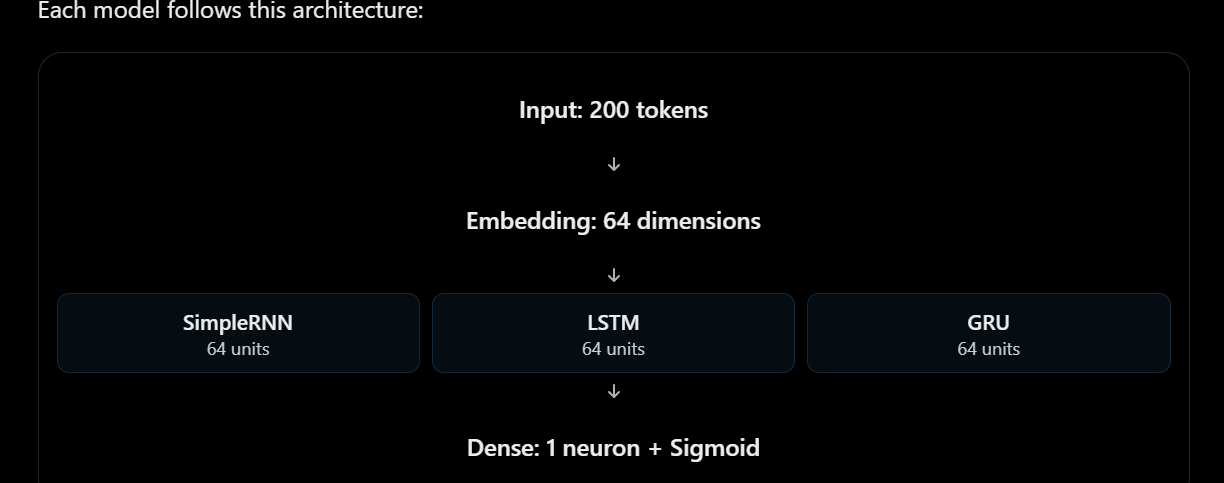

In [18]:

from tensorflow.keras.callbacks import EarlyStopping
import pandas as pd
import time

model_names = ["SimpleRNN", "LSTM", "GRU"]

models = {}
histories = {}
results = []

for name in model_names:

    print(f"\nTraining {name}...")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    current_model = build_model(name)

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    start_time = time.perf_counter()

    current_history = current_model.fit(
        X_tr,
        y_tr,
        validation_data=(X_val, y_val),
        epochs=6,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.perf_counter() - start_time

    val_loss, val_accuracy = current_model.evaluate(
        X_val,
        y_val,
        verbose=0
    )

    models[name] = current_model
    histories[name] = current_history

    results.append({
        "Model": name,
        "Parameters": current_model.count_params(),
        "Val Accuracy (%)": val_accuracy * 100,
        "Val Loss": val_loss,
        "Epochs": len(current_history.history["loss"]),
        "Training Time (sec)": training_time
    })



Training SimpleRNN...
Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 19s 58ms/step - accuracy: 0.6037 - loss: 0.6503 - val_accuracy: 0.7628 - val_loss: 0.5093
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.7886 - loss: 0.4567 - val_accuracy: 0.8018 - val_loss: 0.4658
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.8436 - loss: 0.3616 - val_accuracy: 0.7656 - val_loss: 0.5703
Epoch 4/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 56ms/step - accuracy: 0.8975 - loss: 0.2470 - val_accuracy: 0.7958 - val_loss: 0.6387

Training LSTM...
Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 112ms/step - accuracy: 0.7398 - loss: 0.5112 - val_accuracy: 0.8326 - val_loss: 0.3976
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - accuracy: 0.8748 - loss: 0.3149 - val_accuracy: 0.8520 - val_loss: 0.3936
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 110ms/step - accuracy: 0.9090 - loss: 0.2427 - val_accuracy: 0.8522 - val_loss: 0.3953
Epoch 4/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step

In [19]:

results_df = pd.DataFrame(results)

print(results_df.round(3).to_string(index=False))


    Model  Parameters  Val Accuracy (%)  Val Loss  Epochs  Training Time (sec)
SimpleRNN      648321             80.18     0.466       4               80.740
     LSTM      673089             85.20     0.394       4              146.092
      GRU      665025             84.10     0.382       4              158.586


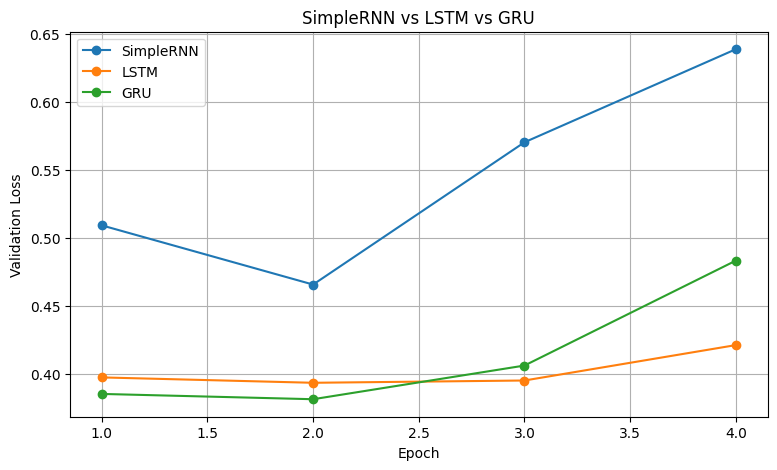

In [20]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for name in model_names:
    val_losses = histories[name].history["val_loss"]

    plt.plot(
        range(1, len(val_losses) + 1),
        val_losses,
        marker="o",
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("SimpleRNN vs LSTM vs GRU")
plt.legend()
plt.grid(True)
plt.show()


In [21]:

best_index = results_df["Val Loss"].idxmin()
best_name = results_df.loc[best_index, "Model"]

print("Best model:", best_name)

best_model = models[best_name]

test_loss, test_accuracy = best_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Best model: GRU
Test Accuracy: 83.48%
Test Loss: 0.3886


In [22]:

for name in model_names:
    losses = histories[name].history["val_loss"]

    best_epoch = np.argmin(losses) + 1

    print(
        f"{name}: "
        f"Best epoch = {best_epoch}, "
        f"Best validation loss = {min(losses):.4f}"
    )


SimpleRNN: Best epoch = 2, Best validation loss = 0.4658
LSTM: Best epoch = 2, Best validation loss = 0.3936
GRU: Best epoch = 2, Best validation loss = 0.3816


SimpleRNN: Simpler architecture and fewer parameters, but it can struggle with long sequences.



LSTM: Uses a gated cell state to support learning dependencies across time.



GRU: Uses a simpler gating structure than LSTM and performed best on validation loss in your current experiment.

In [23]:

best_model = models["GRU"]

test_loss, test_accuracy = best_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(f"GRU Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"GRU Test Loss: {test_loss:.4f}")


GRU Test Accuracy: 83.48%
GRU Test Loss: 0.3886


Bidirectional LSTM

A Bidirectional LSTM uses two separate LSTMs:
- A forward LSTM reads left to right.
- A backward LSTM reads right to left.

An important clarification
A standard LSTM used for whole-review classification already reads the entire sentence before making its final prediction.

Therefore, Bidirectional LSTM is not simply about giving the model access to words it could never see before.

The main difference is how context is represented and learned. Bidirectional LSTM builds representations in both temporal directions, which can make certain relationships easier to learn

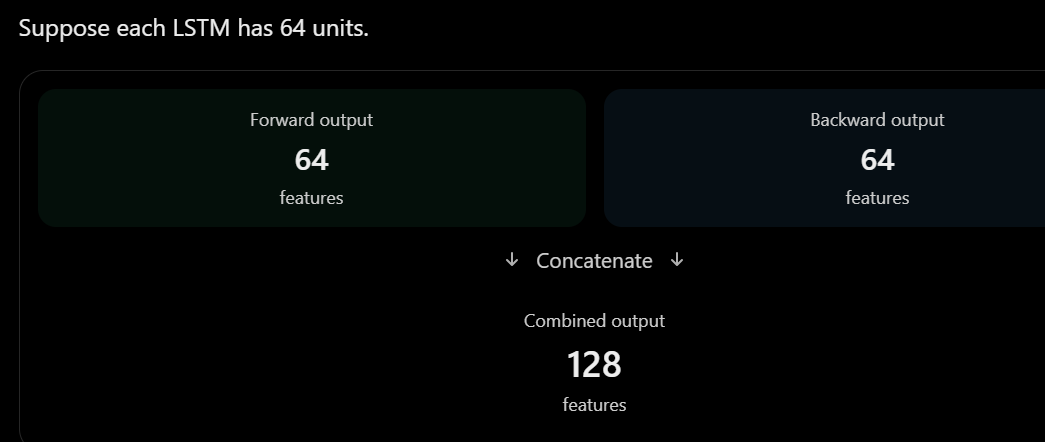

In [24]:

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Embedding,
    Bidirectional,
    LSTM,
    Dense,
    Dropout
)


In [25]:

bilstm_model = Sequential([
    Input(shape=(200,)),

    Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

bilstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,177 (2.69 MB)

 Trainable params: 706,177 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

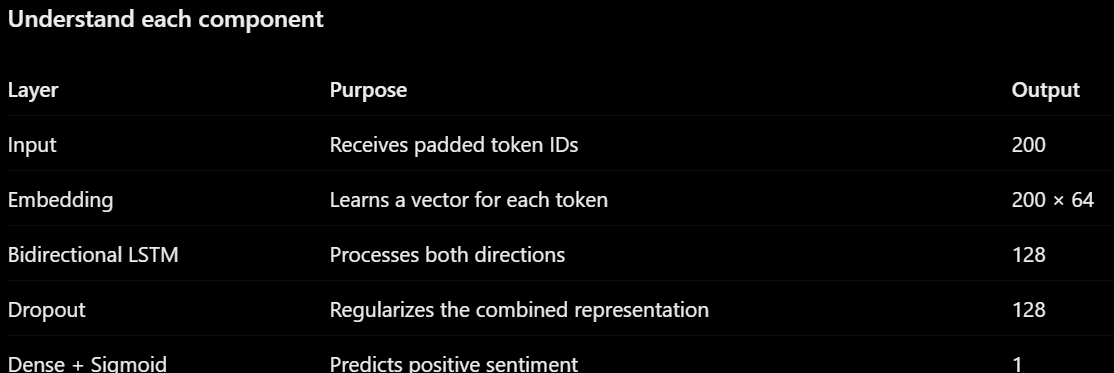

In [26]:

bilstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


In [27]:

from tensorflow.keras.callbacks import EarlyStopping

bilstm_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

bilstm_history = bilstm_model.fit(
    X_tr,
    y_tr,
    validation_data=(X_val, y_val),
    epochs=6,
    batch_size=64,
    callbacks=[bilstm_early_stop]
)


Epoch 1/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 68s 210ms/step - accuracy: 0.7780 - loss: 0.4531 - val_accuracy: 0.8472 - val_loss: 0.3794
Epoch 2/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 66s 210ms/step - accuracy: 0.8968 - loss: 0.2654 - val_accuracy: 0.8550 - val_loss: 0.3639
Epoch 3/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 80s 204ms/step - accuracy: 0.9244 - loss: 0.2027 - val_accuracy: 0.8522 - val_loss: 0.3997
Epoch 4/6
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 206ms/step - accuracy: 0.9329 - loss: 0.1801 - val_accuracy: 0.8536 - val_loss: 0.4512


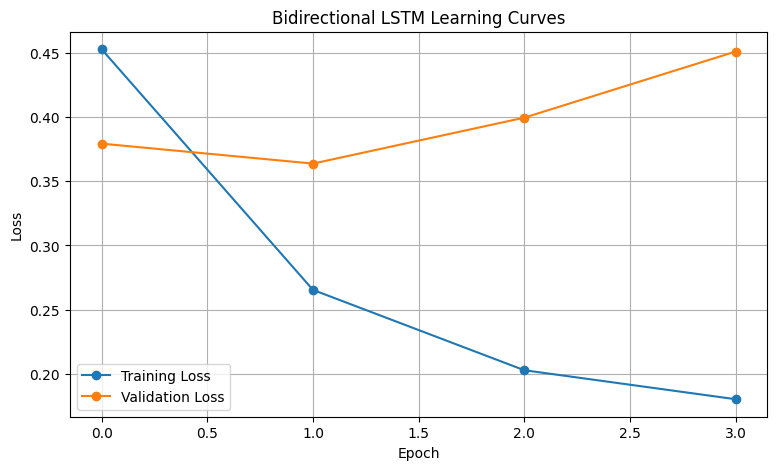

Best validation epoch: 2
Best validation loss: 0.3638595640659332


In [28]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 5))

plt.plot(
    bilstm_history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    bilstm_history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Bidirectional LSTM Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

best_epoch = np.argmin(
    bilstm_history.history["val_loss"]
) + 1

print("Best validation epoch:", best_epoch)

print(
    "Best validation loss:",
    min(bilstm_history.history["val_loss"])
)


In [29]:

# Evaluate Bidirectional LSTM on validation data
bi_val_loss, bi_val_acc = bilstm_model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("Previous models:")

for name in ["SimpleRNN", "LSTM", "GRU"]:
    val_loss, val_acc = models[name].evaluate(
        X_val,
        y_val,
        verbose=0
    )

    print(
        f"{name}: "
        f"Accuracy={val_acc*100:.2f}%, "
        f"Loss={val_loss:.4f}"
    )

print(
    f"Bidirectional LSTM: "
    f"Accuracy={bi_val_acc*100:.2f}%, "
    f"Loss={bi_val_loss:.4f}"
)


Previous models:
SimpleRNN: Accuracy=80.18%, Loss=0.4658
LSTM: Accuracy=85.20%, Loss=0.3936
GRU: Accuracy=84.10%, Loss=0.3816
Bidirectional LSTM: Accuracy=85.50%, Loss=0.3639


Bidirectional LSTMs are useful when the full input sequence is available during inference.

Examples include:
- Movie review sentiment analysis.
- Document classification.
- Named entity recognition.
- Sequence labeling.
- Analyzing complete customer feedback.
But they are less appropriate when a prediction must be made immediately using only past information, such as strictly real-time next-token prediction, because the backward direction requires future sequence positions.


In [30]:

import numpy as np

# Predict positive sentiment probabilities
y_prob = bilstm_model.predict(
    X_val,
    verbose=0
).flatten()

# Convert probabilities into class labels
y_pred = (y_prob >= 0.5).astype(int)

print("First 10 probabilities:")
print(np.round(y_prob[:10], 3))

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 actual labels:")
print(y_val[:10])


First 10 probabilities:
[0.121 0.933 0.148 0.018 0.905 0.062 0.942 0.133 0.047 0.976]

First 10 predicted labels:
[0 1 0 0 1 0 1 0 0 1]

First 10 actual labels:
[1 1 0 0 1 0 1 0 0 1]


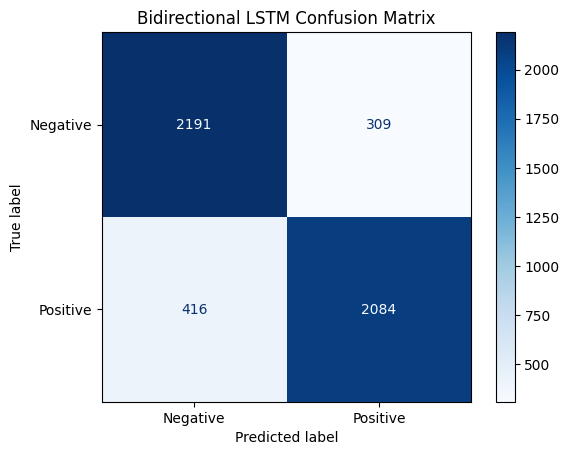

True Negatives: 2191
False Positives: 309
False Negatives: 416
True Positives: 2084


In [31]:

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Bidirectional LSTM Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


In [32]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)


              precision    recall  f1-score   support

    Negative       0.84      0.88      0.86      2500
    Positive       0.87      0.83      0.85      2500

    accuracy                           0.85      5000
   macro avg       0.86      0.85      0.85      5000
weighted avg       0.86      0.85      0.85      5000



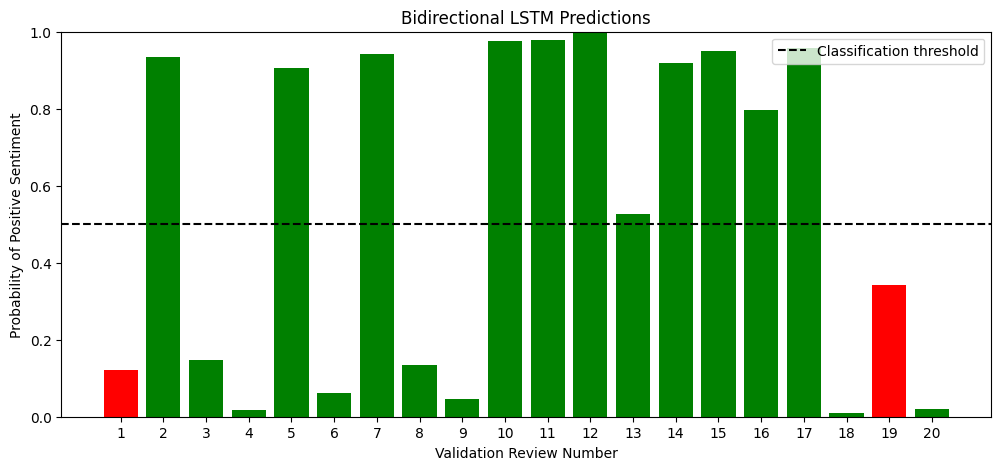

In [33]:

n = 20

colors = [
    "green" if y_pred[i] == y_val[i]
    else "red"
    for i in range(n)
]

plt.figure(figsize=(12, 5))

plt.bar(
    range(1, n + 1),
    y_prob[:n],
    color=colors
)

plt.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    label="Classification threshold"
)

plt.xlabel("Validation Review Number")
plt.ylabel("Probability of Positive Sentiment")
plt.title("Bidirectional LSTM Predictions")
plt.xticks(range(1, n + 1))
plt.ylim(0, 1)
plt.legend()
plt.show()


In [34]:

wrong_indices = np.where(y_pred != y_val)[0]

print("Incorrect validation predictions:", len(wrong_indices))

for idx in wrong_indices[:10]:
    print(
        f"Index: {idx}, "
        f"Actual: {y_val[idx]}, "
        f"Predicted: {y_pred[idx]}, "
        f"Positive probability: {y_prob[idx]:.3f}"
    )


Incorrect validation predictions: 725
Index: 0, Actual: 1, Predicted: 0, Positive probability: 0.121
Index: 18, Actual: 1, Predicted: 0, Positive probability: 0.343
Index: 29, Actual: 1, Predicted: 0, Positive probability: 0.202
Index: 31, Actual: 1, Predicted: 0, Positive probability: 0.155
Index: 32, Actual: 1, Predicted: 0, Positive probability: 0.268
Index: 33, Actual: 1, Predicted: 0, Positive probability: 0.099
Index: 37, Actual: 1, Predicted: 0, Positive probability: 0.018
Index: 47, Actual: 1, Predicted: 0, Positive probability: 0.432
Index: 50, Actual: 1, Predicted: 0, Positive probability: 0.118
Index: 52, Actual: 1, Predicted: 0, Positive probability: 0.078


In [35]:

reverse_word_index = {
    index + 3: word
    for word, index in imdb.get_word_index().items()
}

reverse_word_index.update({
    0: "[PAD]",
    1: "[START]",
    2: "[OOV]",
    3: "[UNUSED]"
})

def decode_review(encoded):
    return " ".join(
        reverse_word_index.get(int(token), "?")
        for token in encoded
        if token != 0
    )

idx = 37

print("Actual sentiment:", y_val[idx])
print("Predicted sentiment:", y_pred[idx])
print("Positive probability:", y_prob[idx])

print("\nReview:")
print(decode_review(X_val[idx]))


Actual sentiment: 1
Predicted sentiment: 0
Positive probability: 0.018467195

Review:
[START] ok this one's a [OOV] honestly i can't tell you all the inner plot points of the beast [OOV] i started losing interest when nothing happened during the first 45 or more minutes but just wait it definitely does pick up br br the plot involves something about a monster in the woods that some french aristocrat chick screwed back in the day eventually you see the beast which looks like a guy dressed in a giant rat bear costume with a horse [OOV] attached to it the scene takes place with the aristocrat woman running around the forest looking for a lost sheep the sheep ends up dead and the woman gets scared the beast pops up rapes the chick and shoots 400 [OOV] of [OOV] all over her eventually the chick starts to enjoy the [OOV] attention which results in some pretty novel [OOV] sex scenes including an [OOV] erotic foot masturbation scene where the woman [OOV] the beast off with her feet while the m

In [52]:

test_loss, test_accuracy = bilstm_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Final Test Loss: {test_loss:.4f}")


Final Test Accuracy: 84.42%
Final Test Loss: 0.3817


In [54]:

import re
import numpy as np

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Load the same vocabulary used by Keras IMDB
word_index = imdb.get_word_index()

def preprocess_review(text):

    # Convert to lowercase and split into word-like tokens
    words = re.findall(
        r"[a-z0-9]+(?:'[a-z0-9]+)?",
        text.lower()
    )

    # 1 is the START token
    encoded = [1]

    for word in words:
        index = word_index.get(word)

        if index is not None and index + 3 < 10000:
            encoded.append(index + 3)
        else:
            encoded.append(2)  # OOV token

    padded = pad_sequences(
        [encoded],
        maxlen=200,
        padding="post",
        truncating="post"
    )

    return padded


def predict_sentiment(text):

    # Convert text to model input
    processed = preprocess_review(text)

    # Get positive sentiment probability
    probability = float(
        bilstm_model.predict(
            processed,
            verbose=0
        )[0][0]
    )

    # Apply classification threshold
    sentiment = (
        "Positive" if probability >= 0.5
        else "Negative"
    )

    print("Review:", text)
    print("Prediction:", sentiment)
    print(f"Positive probability: {probability:.4f}")
    print("-" * 50)

    return sentiment, probability


In [55]:

predict_sentiment(
    "The movie was fantastic and the acting was brilliant"
)

predict_sentiment(
    "The plot was boring and the ending was disappointing"
)

predict_sentiment(
    "The acting was excellent but the story was terrible"
)

predict_sentiment(
    "I thought the movie would be bad but it was surprisingly good"
)


Review: The movie was fantastic and the acting was brilliant
Prediction: Positive
Positive probability: 0.9223
--------------------------------------------------
Review: The plot was boring and the ending was disappointing
Prediction: Negative
Positive probability: 0.0106
--------------------------------------------------
Review: The acting was excellent but the story was terrible
Prediction: Negative
Positive probability: 0.3627
--------------------------------------------------
Review: I thought the movie would be bad but it was surprisingly good
Prediction: Positive
Positive probability: 0.5943
--------------------------------------------------


('Positive', 0.5943372845649719)